# DAY 13 行列式与逆矩阵

## 历史

### 关孝和（日）
1683年，行列式雏形，“解伏题之法”<br>
同一时期 莱布尼茨 发现行列式 <br>
### 莱布尼茨（德）
研究怎么用消元法来表示方程组的解<br>
解的分母总是由系数的某种组合构成<br>
### 凯莱（英）
系统整理并创立了矩阵代数<br>
定义了矩阵乘法，逆矩阵<br>
给出了用行列式证明逆矩阵的公式<br>

$$A^{-1} = \frac{1}{\det(A)} \text{adj}(A)$$

$A^{-1}$ <br>
$$AA^{-1} = A^{-1}A = I$$<br>
$\det(A)$：行列式<br>
$\det(A)≠0$<br>
假设行列式等于0，矩阵奇异，不存在逆矩阵<br>
$\text{adj}(A)$:伴随矩阵 adjugate matrix<br>
1. 求每个元素的代数余子式$C_{ij}$
2. 用代数余子式拼成余子式矩阵
3. 转置，得到$\text{adj}(A)$

$$ 逆矩阵 = 伴随矩阵/原矩阵的行列式$$


**逆矩阵 = 伴随矩阵 除以 原矩阵的行列式**

令 $A = \begin{bmatrix} a & b \\ c & d \end{bmatrix}$

$$\det(A) = ad - bc$$

$$\text{adj}(A) = \begin{bmatrix} d & -b \\ -c & a \end{bmatrix}$$

$$A^{-1} = \frac{1}{ad - bc} \begin{bmatrix} d & -b \\ -c & a \end{bmatrix}$$


高维矩阵（比如5维以上）计算量巨大，工程代码一般不用伴随法求逆，改用LU分解，QR分解<br>
LU分解：上三角U 下三角L<br>
QR分解：Q是正交矩阵，任意两列点积为0  $Q^{T}Q = I$ R上三角矩阵<br>
正交变换不改变向量长度，数值稳定性很强<br>
1. 解线性方程组
2. 最重要的用途：最小二乘法拟合（Regression）
3. 特征值算法：QR迭代，计算机求特征值的经典算法 不断迭代，矩阵收敛到上三角，对角线就是特征值

如何得到QR？
1. 格拉姆斯米特正交法 Gram-Schmit（教学）
2. 豪斯霍尔德反射 HouseHolder反射（工业界常用）
3. 基文斯旋转 Givens旋转（适合稀疏矩阵，只改少量行或者列）



#### SVD 奇异值分解 （Singular Value Decomposition）
任何矩阵都可以拆分成：

$$A_{m \times n} = U_{m \times m} \Sigma_{m \times n} V^T_{n \times n}$$

- **$A_{m \times n}$**：原矩阵（$m \times n$）
- **$U_{m \times m}$**：左奇异矩阵（$m \times m$ 方阵，正交矩阵）
- **$\Sigma_{m \times n}$**：奇异值对角矩阵（$m \times n$）
- **$V^T_{n \times n}$**：右奇异矩阵的转置（$n \times n$ 方阵，正交矩阵）
把任意矩阵拆解成旋转+坐标轴缩放+再旋转 三步几何变换<br>

主要用途：降维PCA，PCA本质SVD的特例；数据压缩，图像压缩（保留前k个大奇异值，丢掉小奇异值）；伪逆Moore-Penrose，长方形矩阵没有逆矩阵，用SVD求逆，求解超定/欠定方程组（最小二乘）；矩阵条件数，最大奇异值/最小奇异值，衡量数值稳定性；推荐系统；NLP词向量（LSA潜在语义分析）；噪声过滤；优化，海森矩阵正定判断，截断SVD做低秩近似。

LU 开销最小，依赖于组元  QR 数值稳定性最好，成本高于LU  SVD 全面

### 西尔韦斯特（英国）
命名：Deteminant 行列式 决定因素 决定方程组有没有唯一解，决定了矩阵能不能求逆
#### 问题源头
##### 面积的缩放
二阶行列式代表着 二维空间里线性变换对面积的缩放比例
##### 解方程组的“分母”
**分母不能为 0** ⇒ **行列式不为 0** ⇒ **方程组有唯一解，矩阵可逆（非奇异矩阵）**。

**分母为 0** ⇒ **行列式为 0** ⇒ **方程组没有唯一解**（空间被“压扁”了，信息丢失了，无法恢复）。
##### 计算机里的行列式
判断数值稳定性的预警指标，矩阵行列式接近零，奇异或者病态


已知变换的结果，求变换前的输入<br>
加密图像，经过矩阵变换，乱码了-->还原方法：逆矩阵（矩阵的后悔药）<br>
多了可以减少，没有不能增加，行列式是逆矩阵存在的前提条件<br>

3×3 矩阵：

$$
A = \begin{pmatrix}
a & b & c \\
d & e & f \\
g & h & i
\end{pmatrix}
$$

行列式：

$$
\det(A) = a(ei - fh) - b(di - fg) + c(dh - eg)
$$

伴随矩阵：

$$
\operatorname{adj}(A) = \begin{pmatrix}
ei - fh & ch - bi & bf - ce \\
fg - di & ai - cg & cd - af \\
dh - eg & bg - ah & ae - bd
\end{pmatrix}
$$

逆矩阵：

$$
A^{-1} = \frac{1}{\det(A)} \operatorname{adj}(A)
$$

核心验证：

$$
A \cdot \operatorname{adj}(A) = \det(A) \cdot I_3
$$

$$
\det(AB) = \det(A)\det(B)
$$

变换的组合，其体积缩放因子等于各个变换缩放因子的乘积。

## 克莱姆法则（Cramer's Rule）
$$
x_{i} = \det(A_{i})\det(A)
$$
$A_{i}$ 是把A的第i列替换成

数学上优美，计算机中计算复杂度极高$O(n*n!)$,计算机中不用克莱姆法则解方程，它只在高维数学证明和理论推导中有用

### 高斯-若尔当求逆法

核心构造：增广矩阵

$[A \mid I]$ $A$行变换，目标把它变成单位矩阵，当左边变成$I$时，右边就变成了$A^{-1}$

本质：用高斯消元法去解n个方程组，复杂度$O(n^{3})$,比克莱姆法则要快很多。

计算机图形学，3d变换；密码学，互质；机器学习，机械臂，雅可比矩阵，机器人的可操作度；

In [5]:
import numpy as  np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print('Success!!!')

Success!!!


In [6]:
A = np.array([[2.0, 1.0], [1.0, 3.0]])
print('det 于算 2*3-1*1 =', 2*3-1*1)
print('det numpy =', np.linalg.det(A))
Ainv = np.linalg.inv(A) # .linalg.inv()逆矩阵计算
print('逆 =\n', Ainv)
print('A @ 逆 =\n', np.round(A @ Ainv, 10))# @ 矩阵的乘法符号 计算出的-0 是因为浮点精读的问题

det 于算 2*3-1*1 = 5
det numpy = 5.000000000000001
逆 =
 [[ 0.6 -0.2]
 [-0.2  0.4]]
A @ 逆 =
 [[ 1.  0.]
 [-0.  1.]]


In [7]:
# 奇异矩阵
B = np.array([[1.0, 2.0], [2.0, 4.0]])

print('det(B)：', np.linalg.det(B))
try:
    print(np.linalg.solve(B, np.array([1.0, 2.0])))
except np.linalg.LinAlgError as e:
    print('solve 报错:', e)
try:
    print(np.linalg.inv(B))
except np.linalg.LinAlgError as e:
    print('inv 报错', e)

det(B)： 0.0
solve 报错: Singular matrix
inv 报错 Singular matrix


列向量矩阵 det =  -21.0 {有向面积}


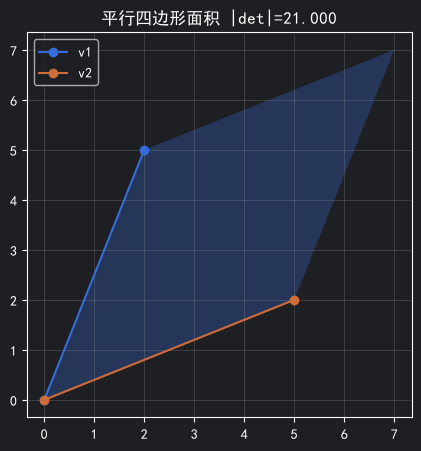

In [8]:
# 两个列向量围成的平行四边的面积
v1,v2 = np.array([2.0,5.0]),np.array([5.0,2.0])
M = np.column_stack([v1,v2])
det = np.linalg.det(M)
print('列向量矩阵 det = ',det,'{有向面积}')
plt.figure(figsize = (5,5))
pts = np.array([[0,0],v1,v1+v2,v2,[0,0]])
plt.fill(pts[:,0],pts[:,1],alpha=0.3)
plt.plot([0,v1[0]],[0,v1[1]],'-o',label ='v1')
plt.plot([0,v2[0]],[0,v2[1]],'-o',label ='v2')
plt.gca().set_aspect('equal')#坐标轴等比例
plt.grid(True, alpha=0.3)
plt.legend()
plt.title(f'平行四边形面积 |det|={abs(det):.3f}')
plt.show()

In [9]:
A = np.array([[2.0,1.0],[1.0,3.0]])
b = np.array([5.0,5.0])
x1 = np.linalg.solve(A,b) #底层用的LU分解，数值稳定，误差小
x2 = np.linalg.inv(A) @ b #多一步求逆，不推荐
print('solve:x1 =',x1)
print('inv@b:x2 =',x2)
print('相同？',np.allclose(x1,x2))
print('优先solve')

solve:x1 = [2. 1.]
inv@b:x2 = [2. 1.]
相同？ True
优先solve
